# Start Here: Images and Your First CNN

> **Who is this for:** a beginner who has never worked with images in code and wants to understand what a **convolutional neural network (CNN)** really does, then train one from scratch.
>
> **What you will learn:**
> - What a digital image is: pixels, grayscale vs colour channels, and the two shape conventions `(H, W, C)` and `(C, H, W)`
> - Simple image operations: crop, flip, brightness, normalisation
> - What a **convolution** does, by applying hand-made 3x3 filters (edge detector, blur) yourself
> - Padding, stride and the output-size formula; pooling
> - How to build **and actually train** a small CNN on handwritten digits on a CPU in seconds, and compare it with simpler baselines
> - How to read loss/accuracy curves, a confusion matrix and the model's mistakes
> - Data augmentation (and when it is wrong), transfer learning in plain words, and how to look inside a trained CNN
>
> **Prerequisites:** [Start Here: PyTorch From Zero](../05_Deep_Learning/00_start_here_pytorch_from_zero.ipynb) (tensors, the 5-step training loop, `nn.Module`). Basic Python ([01_Python/01_basic.ipynb](../01_Python/01_basic.ipynb)) and a little NumPy.
>
> **Time needed:** about 2 hours.
>
> **Runs on:** CPU, no API key, no internet. The dataset (`load_digits`) ships inside scikit-learn. The whole notebook runs in about a minute.

## Roadmap

| Part | Topic |
|---|---|
| 1 | What a digital image is, and simple operations |
| 2 | Convolution by hand: filters, padding, stride, pooling |
| 3 | Train a real CNN on handwritten digits (and compare with baselines) |
| 4 | Data augmentation and transfer learning |
| 5 | Looking inside the trained CNN: filters and feature maps |

In [1]:
import time                                           # timing
import numpy as np                                    # arrays
import matplotlib.pyplot as plt                       # plots
import torch                                          # PyTorch
import torch.nn as nn                                 # layers
import torch.nn.functional as F                       # conv2d, pooling, padding as functions
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import load_digits              # 1,797 small digit images, bundled
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression   # a simple baseline
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

SEED = 0
np.random.seed(SEED); torch.manual_seed(SEED)         # same "random" numbers every run
torch.set_num_threads(2)                              # tiny models run fastest on a couple of CPU threads
NOTEBOOK_START = time.time()
print("PyTorch", torch.__version__)

PyTorch 2.12.1+cpu


**What just happened?**

Libraries loaded and random generators seeded, so your numbers should match the ones described here (tiny differences across PyTorch versions are possible).

---
# Part 1: What is a digital image?

## 1.1 Pixels and grayscale

A digital image is a **grid of numbers**. Each cell is a **pixel** (picture element) and its number is the brightness. A **grayscale** (black-and-white) image has one number per pixel.

scikit-learn's `load_digits` contains 1,797 handwritten digits, each a tiny **8 x 8** grayscale image with brightness values from **0 (white paper) to 16 (full ink)**. Let's look at one as raw numbers and as a picture.

images shape: (1797, 8, 8) | labels shape: (1797,)
pixel values range from 0.0 to 16.0

The first image as numbers (label = 0 ):
[[ 0  0  5 13  9  1  0  0]
 [ 0  0 13 15 10 15  5  0]
 [ 0  3 15  2  0 11  8  0]
 [ 0  4 12  0  0  8  8  0]
 [ 0  5  8  0  0  9  8  0]
 [ 0  4 11  0  1 12  7  0]
 [ 0  2 14  5 10 12  0  0]
 [ 0  0  6 13 10  0  0  0]]


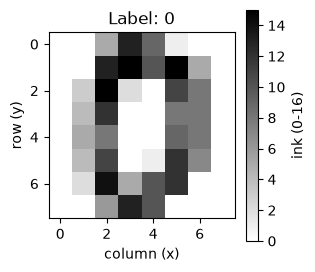

In [2]:
digits = load_digits()                                # bundled with scikit-learn, no download
images, labels = digits.images, digits.target         # images: (1797, 8, 8), labels: (1797,)
print("images shape:", images.shape, "| labels shape:", labels.shape)
print("pixel values range from", images.min(), "to", images.max())

first = images[0]                                     # one 8x8 image
print("\nThe first image as numbers (label =", labels[0], "):")
print(first.astype(int))                              # print as whole numbers

plt.figure(figsize=(3, 3))
plt.imshow(first, cmap="gray_r")                      # gray_r: 0 = white, high = black
plt.title(f"Label: {labels[0]}"); plt.xlabel("column (x)"); plt.ylabel("row (y)")
plt.colorbar(label="ink (0-16)"); plt.show()

**What just happened?**

The grid of numbers *is* the image: high numbers (ink) trace a **0**. When we display it, matplotlib maps each number to a shade. This is all a computer ever "sees": numbers.

Note the axes: **rows** go down (y) and **columns** go across (x). Pixel `[row, column]`, with `[0, 0]` at the top-left corner.

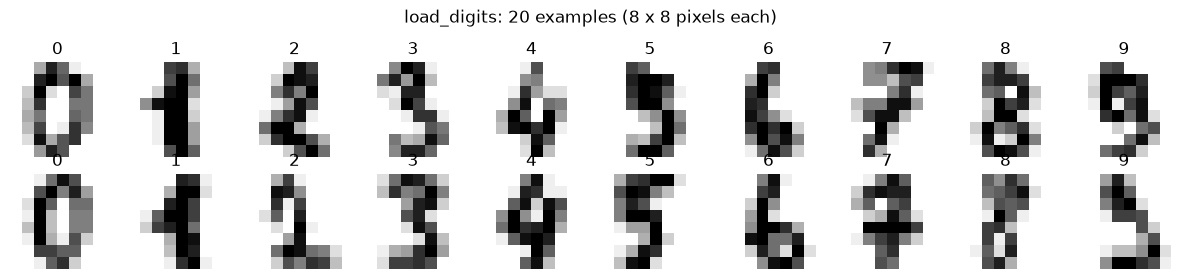

images per class: [178 182 177 183 181 182 181 179 174 180]


In [3]:
fig, axes = plt.subplots(2, 10, figsize=(12, 2.8))
for i, ax in enumerate(axes.ravel()):                 # 20 example digits
    ax.imshow(images[i], cmap="gray_r")
    ax.set_title(str(labels[i])); ax.axis("off")
fig.suptitle("load_digits: 20 examples (8 x 8 pixels each)")
plt.tight_layout(); plt.show()
print("images per class:", np.bincount(labels))

**What just happened?**

Very low resolution, but readable. The 10 classes (digits 0-9) each have roughly 180 images, so the dataset is **balanced**: plain accuracy is a fair score.

## 1.2 Colour images: channels

A colour image stores **three numbers per pixel**: how much **R**ed, **G**reen and **B**lue light to mix. Each of those three grids is called a **channel**. So a colour image is a 3-D tensor.

| Convention | Shape | Used by |
|---|---|---|
| **Channels last** | `(H, W, C)` = (height, width, channels) | NumPy, matplotlib, PIL, OpenCV |
| **Channels first** | `(C, H, W)` | PyTorch |
| Batch of images in PyTorch | `(N, C, H, W)` | PyTorch layers such as `nn.Conv2d` |

Let's build a small synthetic colour image (no download needed) and split it into its channels.

NumPy / matplotlib shape (H, W, C): (48, 48, 3)


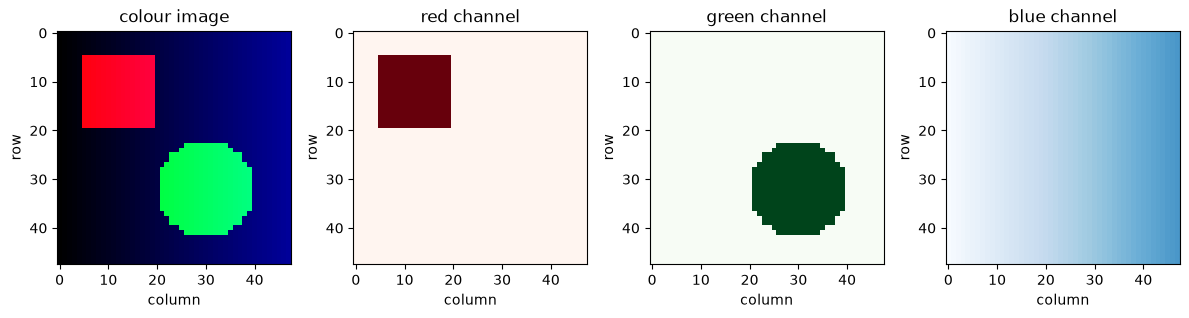

In [4]:
H, W = 48, 48
rgb = np.zeros((H, W, 3), dtype=np.float32)           # (H, W, C), values 0..1, starts black
rgb[:, :, 2] = np.linspace(0, 0.6, W)                 # blue channel: gradient left -> right
rgb[5:20, 5:20, 0] = 1.0                              # red square (top-left)
yy, xx = np.mgrid[0:H, 0:W]                           # row / column coordinate of each pixel
circle = (yy - 32) ** 2 + (xx - 30) ** 2 < 10 ** 2    # True inside a circle of radius 10
rgb[circle, 1] = 1.0                                  # green circle
print("NumPy / matplotlib shape (H, W, C):", rgb.shape)

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
axes[0].imshow(rgb); axes[0].set_title("colour image")
for c, (name, cmap) in enumerate([("red", "Reds"), ("green", "Greens"), ("blue", "Blues")]):
    axes[c + 1].imshow(rgb[:, :, c], cmap=cmap, vmin=0, vmax=1)   # one channel = a grayscale grid
    axes[c + 1].set_title(f"{name} channel")
for ax in axes: ax.set_xlabel("column"); ax.set_ylabel("row")
plt.tight_layout(); plt.show()

**What just happened?**

One colour picture = three stacked grayscale grids. The red square only appears in the red channel, the circle only in the green channel, and the background gradient only in the blue channel. The pixel at `[row, column]` gets its colour by mixing the three values.

In [5]:
t_hwc = torch.from_numpy(rgb)                         # still (H, W, C)
t_chw = t_hwc.permute(2, 0, 1)                        # reorder axes: C first -> (C, H, W)
batch = t_chw.unsqueeze(0)                            # add a batch axis -> (1, C, H, W)
print("(H, W, C):   ", tuple(t_hwc.shape))
print("(C, H, W):   ", tuple(t_chw.shape))
print("(N, C, H, W):", tuple(batch.shape))
back = t_chw.permute(1, 2, 0)                         # back to (H, W, C) for plotting
print("same pixels after the round trip:", torch.equal(back, t_hwc))

(H, W, C):    (48, 48, 3)
(C, H, W):    (3, 48, 48)
(N, C, H, W): (1, 3, 48, 48)
same pixels after the round trip: True


**What just happened?**

`permute(2, 0, 1)` means "the new axis 0 is the old axis 2 (channels), then old axes 0 and 1". No pixel values change, only the order of the axes. `unsqueeze(0)` adds the batch dimension PyTorch layers expect.

> ⚠️ **Common mistake:** using `reshape` instead of `permute` to change `(H, W, C)` into `(C, H, W)`. `reshape` keeps the numbers in memory order and just re-cuts them, which scrambles the image without any error. Use `permute` to reorder axes.

## 1.3 Simple image operations

Because an image is just an array, image editing is just array maths:

| Operation | NumPy code | Meaning |
|---|---|---|
| **Crop** | `img[r0:r1, c0:c1]` | keep a rectangle |
| **Horizontal flip** | `img[:, ::-1]` | mirror left-right (reverse the columns) |
| **Brightness** | `np.clip(img + 0.3, 0, 1)` | add light, then keep values in the valid range |
| **Normalisation** | `(img - mean) / std` | centre values around 0 with spread 1 (what networks like) |

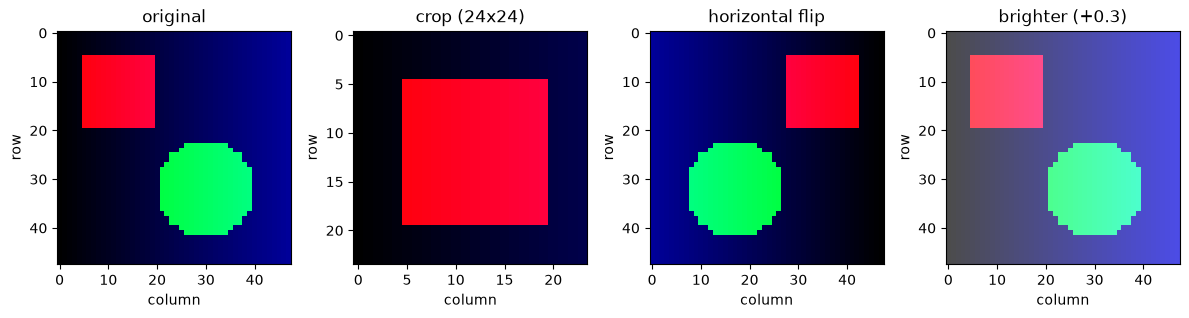

per-channel mean before: [0.098 0.132 0.3  ] after: [0. 0. 0.]
per-channel std  before: [0.297 0.339 0.177] after: [1. 1. 1.]


In [6]:
img = rgb                                             # our synthetic colour image, values 0..1
crop = img[0:24, 0:24]                                # top-left quarter
flip = img[:, ::-1]                                   # reverse column order
bright = np.clip(img + 0.3, 0, 1)                     # brighter, clipped to [0, 1]
mean, std = img.mean(axis=(0, 1)), img.std(axis=(0, 1))   # one mean/std per channel
norm = (img - mean) / std                             # normalised: about mean 0, std 1 per channel

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, (title, im) in zip(axes, [("original", img), ("crop (24x24)", crop),
                                  ("horizontal flip", flip), ("brighter (+0.3)", bright)]):
    ax.imshow(im); ax.set_title(title); ax.set_xlabel("column"); ax.set_ylabel("row")
plt.tight_layout(); plt.show()
print("per-channel mean before:", mean.round(3), "after:", norm.mean(axis=(0, 1)).round(3) + 0.0)  # +0.0 turns -0.0 into 0.0
print("per-channel std  before:", std.round(3),  "after:", norm.std(axis=(0, 1)).round(3))

**What just happened?**

- The crop is smaller (24x24), the flip mirrors the scene, and the bright version is lighter everywhere.
- **Normalisation** is not for looking at (we don't plot it, its values go below 0 and above 1); it is for the model. After it each channel has mean 0 and standard deviation 1. Networks train faster and more reliably when inputs are on this scale.

> 💡 **Tip:** compute the normalisation mean and std on the **training** images only, then apply the same numbers to validation/test images. For the digits below we simply divide by 16 to get values in [0, 1], which is also fine.

---
# Part 2: What a convolution does

## 2.1 The sliding-window idea

A **convolution** slides a small grid of weights, called a **kernel** or **filter** (here 3x3), over the image. At each position it multiplies the 9 overlapping pixels by the 9 kernel weights and adds them up, giving **one output pixel**.

```
 image patch          kernel              output pixel
 [1 2 0]          [ 1  0 -1]
 [4 5 1]    x     [ 2  0 -2]    -> sum of the 9 products = 1+0+0 + 8+0-2 + 2+0-6 = 3
 [2 3 6]          [ 1  0 -1]
 (element-wise multiply, then add everything)
```

Different kernels detect different things: one lights up at vertical edges, another blurs. The key idea of a **CNN**: instead of us designing the kernels by hand, the network **learns** them from data.

Let's implement this ourselves in NumPy first, so there is no magic.

In [7]:
def convolve2d(image, kernel):
    # slide a kernel over a 2-D image ("valid" mode: no padding, stride 1)
    kh, kw = kernel.shape
    out_h, out_w = image.shape[0] - kh + 1, image.shape[1] - kw + 1   # output shrinks
    out = np.zeros((out_h, out_w))
    for r in range(out_h):                            # every row position
        for c in range(out_w):                        # every column position
            patch = image[r:r + kh, c:c + kw]         # the 3x3 window under the kernel
            out[r, c] = np.sum(patch * kernel)        # multiply and add
    return out

patch = np.array([[1, 2, 0], [4, 5, 1], [2, 3, 6]], dtype=float)
sobel_x = np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], dtype=float)   # vertical-edge detector
print("one position by hand:", convolve2d(patch, sobel_x))              # 3x3 image -> 1x1 output

one position by hand: [[3.]]


**What just happened?**

On a 3x3 image the 3x3 kernel fits in exactly one position, and we get the single value **3**, matching the hand calculation in the diagram. Now let's apply some classic kernels to a bigger grayscale image.

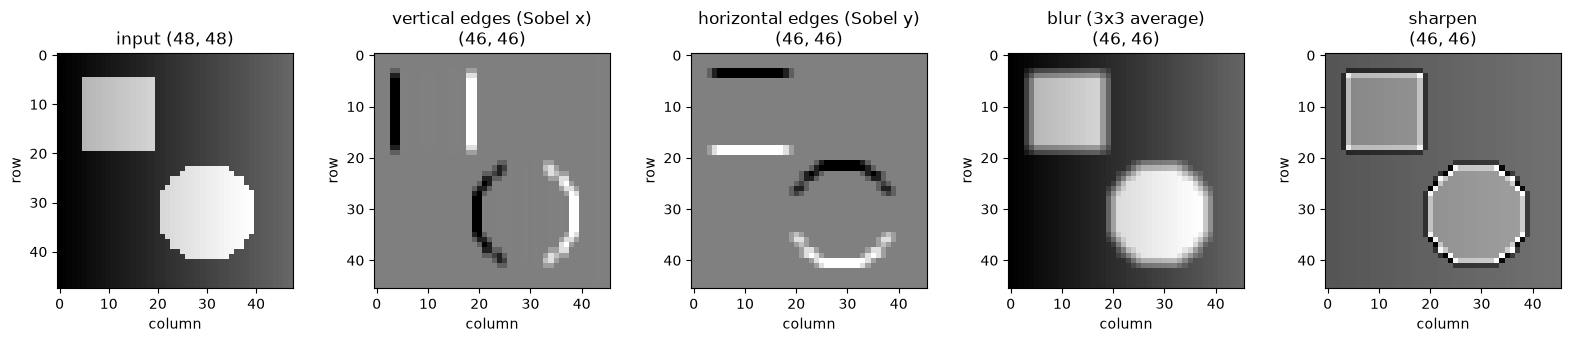

In [8]:
gray = rgb.mean(axis=2)                               # colour -> grayscale by averaging channels
kernels = {
    "vertical edges (Sobel x)":  sobel_x,
    "horizontal edges (Sobel y)": sobel_x.T,          # transpose: rotate the idea 90 degrees
    "blur (3x3 average)":         np.ones((3, 3)) / 9,
    "sharpen":                    np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=float),
}
fig, axes = plt.subplots(1, 5, figsize=(16, 3.2))
axes[0].imshow(gray, cmap="gray"); axes[0].set_title(f"input {gray.shape}")
for ax, (name, k) in zip(axes[1:], kernels.items()):
    res = convolve2d(gray, k)                         # our own loop implementation
    ax.imshow(res, cmap="gray"); ax.set_title(f"{name}\n{res.shape}")
for ax in axes: ax.set_xlabel("column"); ax.set_ylabel("row")
plt.tight_layout(); plt.show()

**What just happened?**

- **Sobel x** responds (bright or dark) only where brightness changes from left to right: the left and right edges of the square and circle. Flat areas give 0 (mid-gray).
- **Sobel y** does the same for top and bottom edges.
- **Blur** replaces each pixel with the average of its 3x3 neighbourhood, softening edges.
- **Sharpen** exaggerates the difference between a pixel and its neighbours.
- Every output is **46x46**, two pixels smaller than the 48x48 input, because a 3x3 window only fits 46 times across 48 pixels. Padding (next) fixes that.

PyTorch's `F.conv2d` does the same computation, just much faster. Let's confirm both agree:

In [9]:
x = torch.tensor(gray, dtype=torch.float32).reshape(1, 1, 48, 48)        # (N=1, C=1, H, W)
k_sobel = torch.tensor(sobel_x, dtype=torch.float32).reshape(1, 1, 3, 3)   # (out_ch, in_ch, kH, kW)
torch_out = F.conv2d(x, k_sobel)                                             # PyTorch convolution
ours = convolve2d(gray, sobel_x)
print("PyTorch output shape:", tuple(torch_out.shape))
print("largest difference vs our loop:", np.abs(torch_out[0, 0].numpy() - ours).max())

PyTorch output shape: (1, 1, 46, 46)
largest difference vs our loop: 1.043081283569336e-07


**What just happened?**

Identical up to tiny floating-point rounding. (Strictly speaking, both compute a **cross-correlation**: the kernel is not flipped first, as in the textbook definition of convolution. Deep learning calls it convolution anyway; since the kernels are learned, the difference does not matter.)

Notice the kernel shape `(out_channels, in_channels, 3, 3)`: a conv layer can read several input channels (e.g. RGB) and produce several output channels (one per learned filter).

## 2.2 Padding, stride and the output-size formula

- **Padding** (`p`): add a border of zeros around the image so the kernel can also sit on the edge pixels. With a 3x3 kernel, `padding=1` keeps the size unchanged.
- **Stride** (`s`): how many pixels the kernel jumps each step. `stride=2` skips every other position and roughly halves the size.

For input size `n`, kernel size `k`, padding `p`, stride `s`:

```
output size = floor( (n + 2p - k) / s ) + 1
```

(`floor` = round down.) Let's check the formula against PyTorch for several settings.

In [10]:
def out_size(n, k, p, s):
    return (n + 2 * p - k) // s + 1                    # // is integer division (rounds down)

print(f"{'n':>3} {'k':>3} {'p':>3} {'s':>3} | {'formula':>7} {'PyTorch':>7}")
for n, k, p, s in [(48, 3, 0, 1), (48, 3, 1, 1), (48, 3, 1, 2), (8, 3, 1, 1), (8, 5, 0, 1), (7, 3, 0, 2)]:
    conv = nn.Conv2d(1, 1, kernel_size=k, padding=p, stride=s)        # a conv layer with these settings
    actual = conv(torch.zeros(1, 1, n, n)).shape[-1]                   # run it on a dummy image
    print(f"{n:>3} {k:>3} {p:>3} {s:>3} | {out_size(n, k, p, s):>7} {actual:>7}")

  n   k   p   s | formula PyTorch
 48   3   0   1 |      46      46
 48   3   1   1 |      48      48
 48   3   1   2 |      24      24
  8   3   1   1 |       8       8
  8   5   0   1 |       4       4
  7   3   0   2 |       3       3


**What just happened?**

The formula matches PyTorch in every row:
- `48, k=3, p=0` → 46 (shrinks by 2, as we saw above).
- `48, k=3, p=1` → 48 ("same" size: the usual choice).
- `48, k=3, p=1, s=2` → 24 (stride 2 halves it).
- `7, k=3, p=0, s=2` → 3: `(7 - 3) / 2 + 1 = 3`.

> 💡 **Tip:** when designing a CNN, write the shape after every layer in a comment. Shape mistakes are the most common CNN bug.

## 2.3 Pooling

**Max pooling** shrinks an image by keeping only the largest value in each small window (usually 2x2, stride 2). It keeps "was this feature present in this region?" while throwing away the exact position, which makes the network a bit more tolerant of small shifts and reduces the amount of computation.

input 4x4:
 tensor([[1., 3., 2., 0.],
        [5., 6., 1., 2.],
        [0., 2., 9., 4.],
        [1., 1., 3., 8.]])
max-pooled 2x2:
 tensor([[6., 2.],
        [2., 9.]])


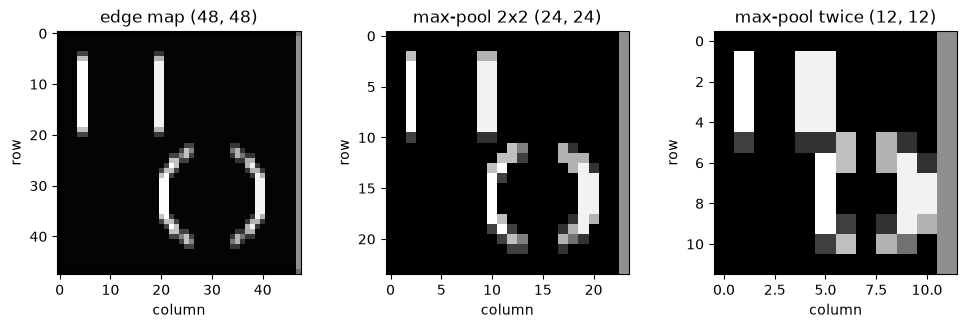

In [11]:
small = torch.tensor([[1., 3., 2., 0.],
                      [5., 6., 1., 2.],
                      [0., 2., 9., 4.],
                      [1., 1., 3., 8.]]).reshape(1, 1, 4, 4)
pooled = F.max_pool2d(small, kernel_size=2)           # 2x2 windows, stride 2 by default
print("input 4x4:\n", small[0, 0])
print("max-pooled 2x2:\n", pooled[0, 0])

edges = F.conv2d(x, k_sobel, padding=1).abs()               # Sobel-x edge strength, 48x48
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
for ax, (title, im) in zip(axes, [("edge map", edges), ("max-pool 2x2", F.max_pool2d(edges, 2)),
                                  ("max-pool twice", F.max_pool2d(edges, 4))]):
    ax.imshow(im[0, 0], cmap="gray"); ax.set_title(f"{title} {tuple(im.shape[-2:])}")
    ax.set_xlabel("column"); ax.set_ylabel("row")
plt.tight_layout(); plt.show()

**What just happened?**

- Top-left 2x2 window `[1, 3, 5, 6]` → 6; top-right `[2, 0, 1, 2]` → 2; bottom-left `[0, 2, 1, 1]` → 2; bottom-right `[9, 4, 3, 8]` → 9.
- On the edge map, each pooling step halves the size (48 → 24 → 12) but the edges are still clearly there, just coarser.
- Notice the gray stripe along the right border of the edge map. That is an artefact of **zero padding**: the background there is bright blue-ish, and the zeros added outside the image look like a sudden drop in brightness, i.e. a fake edge. Real CNNs live with this (or use other padding modes); it is just good to know where such stripes come from.

A typical CNN block is therefore: **convolution → ReLU → pooling**, repeated a few times, followed by ordinary `nn.Linear` layers that make the final decision.

---
# Part 3: Train a real CNN on handwritten digits

## 3.1 Prepare the data

Steps:
1. Scale pixel values from 0-16 to 0-1 (divide by 16).
2. Add the channel axis: `(N, 8, 8)` → `(N, 1, 8, 8)` (1 channel = grayscale).
3. Split into **train (60%)**, **validation (20%)** for watching training, and **test (20%)** for the final, untouched score.

In [12]:
X_all = images.astype(np.float32) / 16.0                      # scale to [0, 1]
idx = np.arange(len(X_all))
idx_tr, idx_tmp = train_test_split(idx, test_size=0.4, random_state=SEED, stratify=labels)
idx_va, idx_te = train_test_split(idx_tmp, test_size=0.5, random_state=SEED, stratify=labels[idx_tmp])

def to_tensors(ix):
    X = torch.tensor(X_all[ix]).unsqueeze(1)                  # (n, 1, 8, 8): add channel axis
    y = torch.tensor(labels[ix], dtype=torch.long)            # class labels as int64
    return X, y

X_tr, y_tr = to_tensors(idx_tr); X_va, y_va = to_tensors(idx_va); X_te, y_te = to_tensors(idx_te)
print("train:", tuple(X_tr.shape), "validation:", tuple(X_va.shape), "test:", tuple(X_te.shape))

train: (1078, 1, 8, 8) validation: (359, 1, 8, 8) test: (360, 1, 8, 8)


**What just happened?**

1,078 training, 359 validation and 360 test images, each shaped `(1, 8, 8)`. `stratify` keeps the same mix of digits in every split.

## 3.2 Baselines first

Before building a CNN, measure simple models. If a CNN cannot beat them, it is not worth the complexity.

- **Logistic regression** (scikit-learn): a linear model on the 64 pixel values.
- **MLP** (multi-layer perceptron): an ordinary neural network that flattens the image into 64 numbers, ignoring which pixels are neighbours.

In [13]:
logreg = LogisticRegression(max_iter=2000)                     # linear classifier
logreg.fit(X_tr.reshape(len(X_tr), -1).numpy(), y_tr.numpy())  # flatten to (n, 64)
acc_logreg = logreg.score(X_te.reshape(len(X_te), -1).numpy(), y_te.numpy())
print(f"logistic regression test accuracy: {acc_logreg:.3f}")

logistic regression test accuracy: 0.967


**What just happened?**

Logistic regression already reaches about **96-97%** on these clean, centred digits. That is a strong baseline: the bar for our CNN is high.

## 3.3 One training function for every model

We reuse the 5-step loop from the PyTorch start-here notebook, with mini-batches from a `DataLoader`, and record the training loss, validation loss and validation accuracy after each **epoch**. The optional `augment` argument is used in Part 4.

In [14]:
loss_fn = nn.CrossEntropyLoss()

def evaluate(model, X, y):
    model.eval()                                      # eval mode: dropout off
    with torch.no_grad():                             # no gradients needed
        logits = model(X)
        return loss_fn(logits, y).item(), (logits.argmax(1) == y).float().mean().item()

def fit(model, epochs=30, lr=3e-3, augment=None, seed=SEED):
    torch.manual_seed(seed)                           # same batches every run
    loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=64, shuffle=True)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "val_loss": [], "val_acc": []}
    for epoch in range(epochs):
        model.train(); total = 0.0
        for xb, yb in loader:
            if augment is not None: xb = augment(xb)  # optional: change the images a little
            loss = loss_fn(model(xb), yb)             # 1-2: forward + loss
            opt.zero_grad(); loss.backward(); opt.step()   # 3-5: clear, backward, update
            total += loss.item() * len(xb)
        hist["train_loss"].append(total / len(X_tr))
        vl, va = evaluate(model, X_va, y_va)
        hist["val_loss"].append(vl); hist["val_acc"].append(va)
    return hist

**What just happened?**

Only definitions so far. `fit` loops over epochs; inside, it loops over shuffled batches of 64 images and performs the five training steps. After each epoch it evaluates on the validation set.

In [15]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),                               # (N, 1, 8, 8) -> (N, 64): forget the 2-D layout
            nn.Linear(64, 128), nn.ReLU(),
            nn.Linear(128, 10))                          # 10 scores, one per digit
    def forward(self, x):
        return self.net(x)

torch.manual_seed(SEED)
mlp = MLP()
t0 = time.time()
hist_mlp = fit(mlp)
acc_mlp = evaluate(mlp, X_te, y_te)[1]
print(f"MLP: {sum(p.numel() for p in mlp.parameters()):,} parameters | "
      f"test accuracy {acc_mlp:.3f} | trained in {time.time() - t0:.1f} s")

MLP: 9,610 parameters | test accuracy 0.975 | trained in 12.6 s


**What just happened?**

The MLP trains quickly (a few seconds on an idle laptop; longer on a busy machine) and lands in the same range as logistic regression (about 97-98%). It treats the image as a flat list of 64 numbers: if we shuffled the pixel order consistently for every image, it would learn just as well. It has no idea that neighbouring pixels belong together.

## 3.4 The CNN

A CNN *does* use the 2-D layout: each filter looks at a small neighbourhood, and the **same** filter is reused at every position (a stroke is a stroke wherever it appears). Our architecture, with the shape after each layer:

```
input                                  (N,  1, 8, 8)
Conv2d(1 -> 16, 3x3, padding=1) + ReLU (N, 16, 8, 8)   16 learned filters
MaxPool 2x2                            (N, 16, 4, 4)
Conv2d(16 -> 32, 3x3, padding=1) + ReLU(N, 32, 4, 4)   32 filters that combine the first 16
MaxPool 2x2                            (N, 32, 2, 2)
Flatten                                (N, 128)        32 * 2 * 2 = 128
Linear(128 -> 64) + ReLU + Dropout     (N, 64)
Linear(64 -> 10)                       (N, 10)         one raw score (logit) per digit
```

In [16]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(                       # the "seeing" part
            nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.classifier = nn.Sequential(                     # the "deciding" part
            nn.Flatten(), nn.Linear(32 * 2 * 2, 64), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(64, 10))
    def forward(self, x):
        return self.classifier(self.features(x))

torch.manual_seed(SEED)
cnn = SmallCNN()
h = X_tr[:5]                                                 # a dummy batch of 5 images
print(f"{'input':<12} {tuple(h.shape)}")
for layer in list(cnn.features) + list(cnn.classifier):     # walk through every layer
    h = layer(h)
    print(f"{layer.__class__.__name__:<12} {tuple(h.shape)}")
print("parameters:", sum(p.numel() for p in cnn.parameters()))

input        (5, 1, 8, 8)
Conv2d       (5, 16, 8, 8)
ReLU         (5, 16, 8, 8)
MaxPool2d    (5, 16, 4, 4)
Conv2d       (5, 32, 4, 4)
ReLU         (5, 32, 4, 4)
MaxPool2d    (5, 32, 2, 2)
Flatten      (5, 128)
Linear       (5, 64)
ReLU         (5, 64)
Dropout      (5, 64)
Linear       (5, 10)
parameters: 13706


**What just happened?**

Pushing 5 real images through the untrained network layer by layer confirms the shapes in the diagram: `(5, 1, 8, 8)` → ... → `(5, 10)`. Doing this "shape walk" before training catches most architecture bugs.

The CNN has 13,706 parameters, somewhat more than the MLP's 9,610. But look where they live: the two conv layers together have only `(16·1·9 + 16) + (32·16·9 + 32) = 160 + 4,640 = 4,800`, because each small 3x3 filter is **shared** across every position of the image. Most of the parameters sit in the final `Linear` layers.

CNN trained in 11.2 s | final val acc 0.986 | test acc 0.983


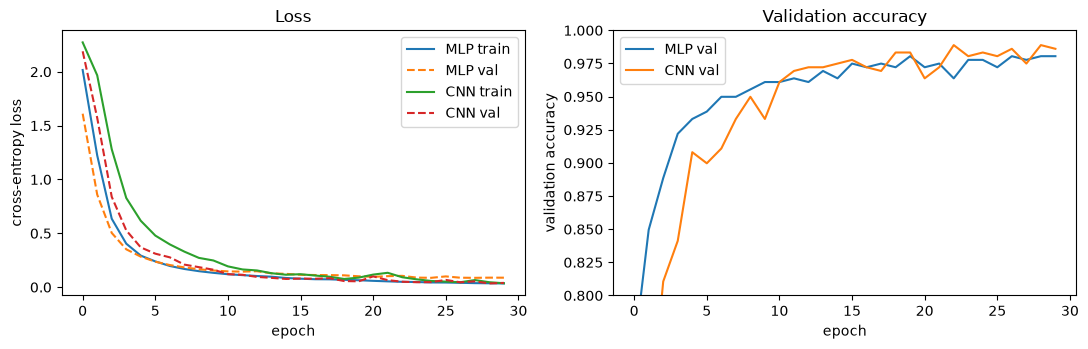

In [17]:
t0 = time.time()
hist_cnn = fit(cnn)                                          # same training recipe as the MLP
cnn_time = time.time() - t0
acc_cnn = evaluate(cnn, X_te, y_te)[1]
print(f"CNN trained in {cnn_time:.1f} s | final val acc {hist_cnn['val_acc'][-1]:.3f} | test acc {acc_cnn:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for name, hh in [("MLP", hist_mlp), ("CNN", hist_cnn)]:
    axes[0].plot(hh["train_loss"], label=f"{name} train"); axes[0].plot(hh["val_loss"], "--", label=f"{name} val")
    axes[1].plot(hh["val_acc"], label=f"{name} val")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("cross-entropy loss"); axes[0].set_title("Loss"); axes[0].legend()
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("validation accuracy"); axes[1].set_title("Validation accuracy")
axes[1].set_ylim(0.8, 1.0); axes[1].legend(); plt.tight_layout(); plt.show()

**What just happened?**

- The CNN trains on the CPU in seconds (exact time depends on your machine).
- **Loss:** training and validation loss both fall and flatten; validation stays close to training, so there is no serious overfitting.
- **Accuracy:** both models climb quickly and flatten out in the high 90s.

In [18]:
print(f"{'model':<22}{'test accuracy':>14}")
for name, acc in [("logistic regression", acc_logreg), ("MLP", acc_mlp), ("CNN", acc_cnn)]:
    print(f"{name:<22}{acc:>14.3f}")

model                  test accuracy
logistic regression            0.967
MLP                            0.975
CNN                            0.983


**What just happened?**

On this dataset the CNN is the best of the three, but the margin is small. That is an honest and important lesson: these 8x8 digits are tiny, clean and centred, so even a linear model does well. CNNs shine on **larger, messier images** (photos with backgrounds, objects at different positions and sizes), where flat models fall far behind. Part 4 shows one such situation: shifted digits.

## 3.5 Where does the CNN make mistakes?

A **confusion matrix** is a table: rows = true digit, columns = predicted digit. The diagonal counts correct answers; anything off the diagonal is a mistake, and *which* cell tells you what got confused with what.

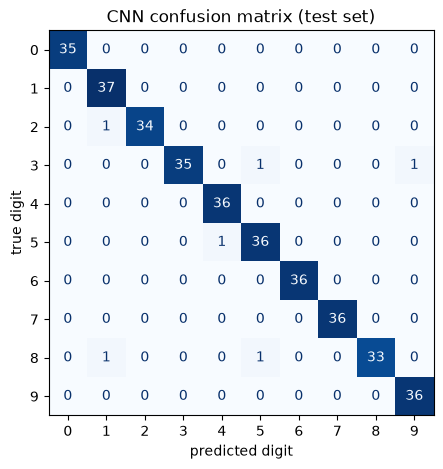

correct: 354 of 360 | mistakes: 6


In [19]:
cnn.eval()
with torch.no_grad():
    pred_te = cnn(X_te).argmax(1)                              # predicted digit for each test image
cm = confusion_matrix(y_te.numpy(), pred_te.numpy())
fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(ax=ax, colorbar=False, cmap="Blues")
ax.set_xlabel("predicted digit"); ax.set_ylabel("true digit"); ax.set_title("CNN confusion matrix (test set)")
plt.show()
print("correct:", int(np.trace(cm)), "of", int(cm.sum()), "| mistakes:", int(cm.sum() - np.trace(cm)))

**What just happened?**

Almost every count sits on the diagonal. The few off-diagonal cells show which digits the CNN confuses. Let's look at the actual mistaken images:

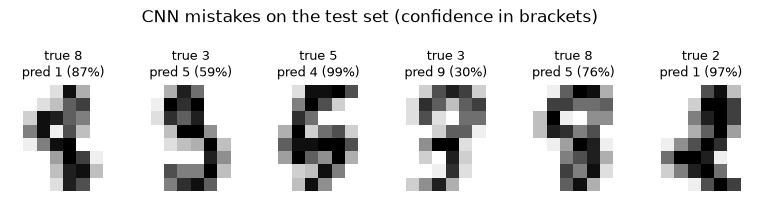

In [20]:
wrong = torch.nonzero(pred_te != y_te).flatten()               # indices of mistakes
with torch.no_grad():
    probs = F.softmax(cnn(X_te[wrong]), dim=1)                 # model confidence for those images
n_show = min(len(wrong), 10)
fig, axes = plt.subplots(1, n_show, figsize=(1.6 * n_show, 2.2), squeeze=False)
for ax, j, p in zip(axes[0], wrong[:n_show], probs[:n_show]):
    ax.imshow(X_te[j, 0], cmap="gray_r")
    ax.set_title(f"true {y_te[j].item()}\npred {pred_te[j].item()} ({p.max():.0%})", fontsize=9)
    ax.axis("off")
fig.suptitle("CNN mistakes on the test set (confidence in brackets)", y=1.08)
plt.show()

**What just happened?**

Look at the images: several of the mistakes are genuinely ambiguous or badly written even for a human at 8x8 resolution. Looking at the errors is one of the most useful habits in machine learning: it tells you whether the model needs more data, a different design, or whether the labels themselves are questionable.

---
# Part 4: Data augmentation and transfer learning

## 4.1 Why augmentation?

**Data augmentation** means creating slightly changed copies of the training images on the fly (shifted, flipped, rotated, brighter...) while keeping the label. The model sees more variety, so it learns what really matters about a "3" instead of memorising exact pixel positions. It is free extra data.

The golden rule: **an augmentation must not change the correct label.** Flipping a photo of a cat left-right still shows a cat. But flipping a digit is a bad idea:

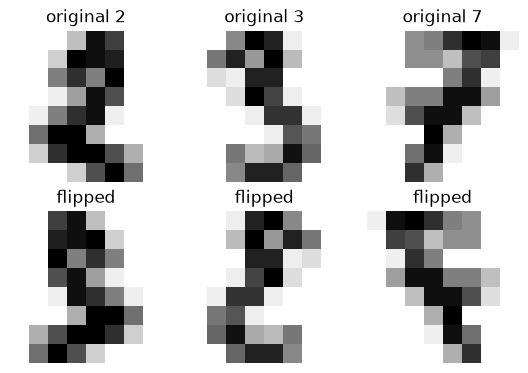

In [21]:
examples = [np.where(labels == d)[0][0] for d in (2, 3, 7)]     # first image of a 2, 3 and 7
fig, axes = plt.subplots(2, 3, figsize=(5.5, 3.8))
for col, i in enumerate(examples):
    axes[0, col].imshow(images[i], cmap="gray_r"); axes[0, col].set_title(f"original {labels[i]}")
    axes[1, col].imshow(images[i][:, ::-1], cmap="gray_r"); axes[1, col].set_title("flipped")
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.show()

**What just happened?**

A flipped 2, 3 or 7 is no longer a valid digit, so random flips would teach the model nonsense. For digits, small **shifts** are a label-preserving augmentation: a 3 moved one pixel to the left is still a 3. Always ask "would a human still give this the same label?"

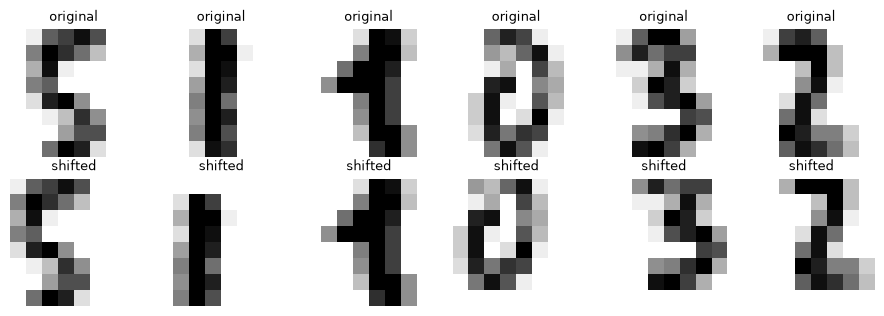

In [22]:
def random_shift(xb, max_shift=1):
    # move every image in the batch by a random -1, 0 or +1 pixels up/down and left/right
    padded = F.pad(xb, (max_shift,) * 4)              # zero border on all four sides: 8x8 -> 10x10
    out = torch.empty_like(xb)
    for i in range(len(xb)):                          # a different random shift per image
        dy, dx = torch.randint(0, 2 * max_shift + 1, (2,)).tolist()
        out[i] = padded[i, :, dy:dy + 8, dx:dx + 8]   # cut an 8x8 window from the padded image
    return out

torch.manual_seed(1)
demo = random_shift(X_tr[:6])
fig, axes = plt.subplots(2, 6, figsize=(9, 3.2))
for i in range(6):
    axes[0, i].imshow(X_tr[i, 0], cmap="gray_r"); axes[0, i].set_title("original", fontsize=9)
    axes[1, i].imshow(demo[i, 0], cmap="gray_r"); axes[1, i].set_title("shifted", fontsize=9)
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.show()

**What just happened?**

Each image moved by up to one pixel in a random direction (some by zero), with blank paper filling the gap. Every training epoch the network now sees slightly different versions of the same digits.

To see *why* this matters, we build a **shifted test set**: the same test images, each moved one pixel in a random direction. This simulates real-world data that is not perfectly centred. Then we compare all models, including a CNN trained with augmentation.

In [23]:
def shift_by(x, dy, dx):                                  # move one image by (dy, dx) pixels
    p = F.pad(x, (1, 1, 1, 1))                            # 8x8 -> 10x10 with a zero border
    return p[:, 1 - dy:9 - dy, 1 - dx:9 - dx]

rng = np.random.default_rng(SEED)
moves = [(dy, dx) for dy in (-1, 0, 1) for dx in (-1, 0, 1) if (dy, dx) != (0, 0)]   # 8 directions
X_te_shift = torch.stack([shift_by(x, *moves[rng.integers(len(moves))]) for x in X_te])

torch.manual_seed(SEED)
cnn_aug = SmallCNN()
t0 = time.time()
hist_aug = fit(cnn_aug, epochs=60, augment=random_shift)   # same recipe + augmentation, 60 epochs
print(f"augmented CNN trained in {time.time() - t0:.1f} s")

augmented CNN trained in 24.1 s


**What just happened?**

`X_te_shift` holds every test image moved by exactly one pixel (in one of 8 directions).

We trained the augmented CNN for **60** epochs instead of 30: because it sees a slightly different version of every image each time, the task is harder and learning takes longer. (Is that unfair to the plain CNN? Training the plain CNN for 60 epochs as well hardly changes its shifted-test score; you can check this yourself in Exercise 4.) Now the comparison:

In [24]:
Xf, Xf_shift = X_te.reshape(len(X_te), -1).numpy(), X_te_shift.reshape(len(X_te), -1).numpy()
rows = [("logistic regression", logreg.score(Xf, y_te.numpy()), logreg.score(Xf_shift, y_te.numpy())),
        ("MLP", evaluate(mlp, X_te, y_te)[1], evaluate(mlp, X_te_shift, y_te)[1]),
        ("CNN", evaluate(cnn, X_te, y_te)[1], evaluate(cnn, X_te_shift, y_te)[1]),
        ("CNN + shift augmentation", evaluate(cnn_aug, X_te, y_te)[1], evaluate(cnn_aug, X_te_shift, y_te)[1])]
print(f"{'model':<27}{'normal test':>12}{'shifted test':>14}")
for name, a, b in rows:
    print(f"{name:<27}{a:>12.3f}{b:>14.3f}")

model                       normal test  shifted test
logistic regression               0.967         0.264
MLP                               0.975         0.306
CNN                               0.983         0.533
CNN + shift augmentation          0.992         0.978


**What just happened?**

This table is the most important result in the notebook:

- A **one-pixel shift** is devastating for the flat models: logistic regression drops from about 97% to about 26%, the MLP to about 31%. They learned rules like "ink at pixel number 27 suggests a 3"; moving the digit moves the ink to different pixel numbers, and the rules no longer apply.
- The **plain CNN** holds up better (about 53%) thanks to its shared filters and pooling, but it is far from robust: on an 8x8 image one pixel is 12% of the width, and its final `Linear` layer still cares about *where* features appear.
- The **CNN trained with shift augmentation** keeps about 98% on shifted digits, and it is also slightly *better* on the normal test set (about 99%). It has learned what a digit looks like, not where its ink usually sits.

Lesson: architecture (CNN) and data (augmentation) work together. Augmentation is one of the cheapest, most effective tools in computer vision.

## 4.2 Transfer learning (in words)

Training a CNN from scratch needs lots of images. **Transfer learning** reuses a network that someone already trained on a huge, general image collection (for example ImageNet, about 1.2 million photos in 1,000 categories). Its early filters already detect edges, textures and shapes, which are useful for almost any image task.

The usual recipe:

| Step | What you do | Why |
|---|---|---|
| 1 | Download a **pretrained** model (e.g. a ResNet) | get filters that already "see" well |
| 2 | **Freeze** its layers (`requires_grad = False`) | keep that knowledge, train much faster |
| 3 | Replace the final layer with a new one sized for *your* classes | the old one predicts the 1,000 ImageNet classes |
| 4 | Train only the new layer on your (small) dataset | often works with a few hundred images per class |
| 5 | Optionally **fine-tune**: unfreeze some layers and train with a small learning rate | squeeze out extra accuracy |

In code (with `torchvision`) it looks like this. **We do not run it here** because the pretrained weights are downloaded from the internet the first time (tens of megabytes), and this notebook is designed to run offline:

```python
from torchvision.models import resnet18, ResNet18_Weights

model = resnet18(weights=ResNet18_Weights.DEFAULT)      # needs internet the first time (then cached)
for p in model.parameters():
    p.requires_grad = False                              # freeze the pretrained "seeing" layers
model.fc = nn.Linear(model.fc.in_features, 10)           # new final layer for 10 classes (trainable)
optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
# Inputs must look like the pretraining data: 3-channel colour images (typically 224x224),
# normalised with the same mean/std that the weights were trained with (weights.transforms() gives them).
```

> 💡 **Tip:** for real-world image projects, starting from a pretrained model is the default choice and usually beats training from scratch, especially with little data. Training from scratch (as we did) is how you learn what is going on inside.

---
# Part 5: Looking inside the trained CNN

## 5.1 The learned first-layer filters

Our first conv layer has 16 filters of size 3x3. In Part 2 *we* chose filters such as Sobel; now let's see what the network chose for itself.

first-layer filter tensor shape: (16, 1, 3, 3)


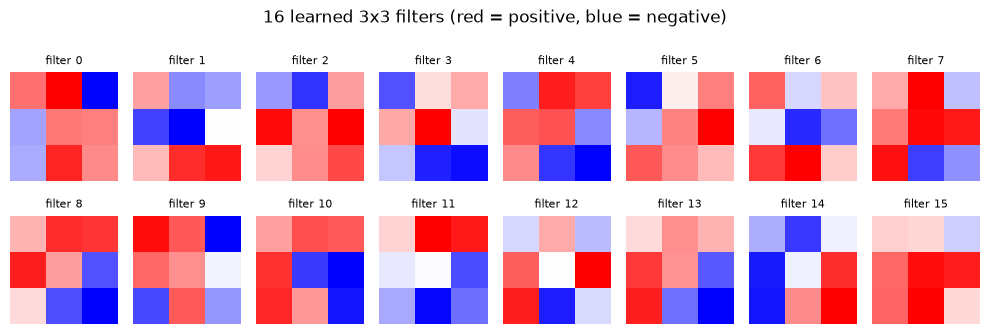

In [25]:
filters = cnn.features[0].weight.detach()            # shape (16, 1, 3, 3)
print("first-layer filter tensor shape:", tuple(filters.shape))
fig, axes = plt.subplots(2, 8, figsize=(10, 3.6))
for i, ax in enumerate(axes.ravel()):
    f = filters[i, 0]
    lim = f.abs().max()                               # symmetric colour scale: 0 is white
    ax.imshow(f, cmap="bwr", vmin=-lim, vmax=lim)     # red = positive weight, blue = negative
    ax.set_title(f"filter {i}", fontsize=8); ax.axis("off")
fig.suptitle("16 learned 3x3 filters (red = positive, blue = negative)")
plt.tight_layout(); plt.show()

**What just happened?**

Each tiny square is one learned kernel. Many show a red side next to a blue side, which is exactly the pattern of an **edge detector** like Sobel: they respond where brightness changes in a particular direction. Others look more like blobs or diagonal detectors. Nobody told the network to build edge detectors; it discovered they are useful for recognising digits. (With 3x3 filters and 8x8 images these are rough; on large photos, first-layer filters look strikingly like clean edge and colour detectors.)

## 5.2 Feature maps: what each filter "sees"

A **feature map** is the output of one filter applied to one image: bright where the filter's pattern is present.

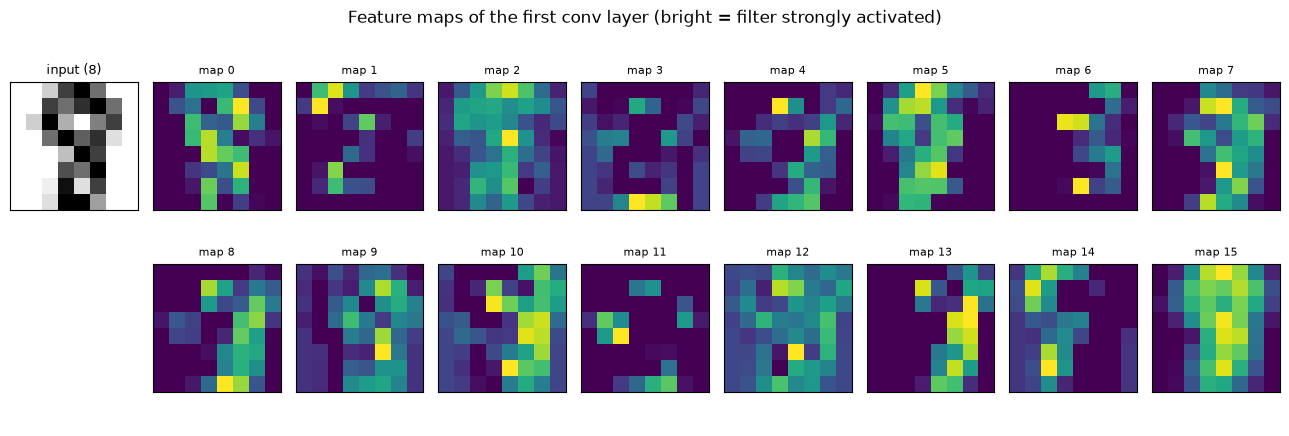

In [26]:
img_idx = 0
sample = X_te[img_idx:img_idx + 1]                   # one test image, shape (1, 1, 8, 8)
cnn.eval()
with torch.no_grad():
    fmap = F.relu(cnn.features[0](sample))[0]         # conv1 + ReLU -> (16, 8, 8)

fig, axes = plt.subplots(2, 9, figsize=(13, 4.4))
axes[0, 0].imshow(sample[0, 0], cmap="gray_r"); axes[0, 0].set_title(f"input ({y_te[img_idx].item()})", fontsize=9)
axes[1, 0].axis("off")
for i, ax in enumerate(axes[:, 1:].ravel()):
    ax.imshow(fmap[i], cmap="viridis"); ax.set_title(f"map {i}", fontsize=8)
for ax in axes.ravel(): ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Feature maps of the first conv layer (bright = filter strongly activated)")
plt.tight_layout(); plt.show()

**What just happened?**

Each of the 16 maps highlights different parts of the same digit: some light up along left edges of strokes, some along right or top edges, some on the stroke itself or on the background. The second conv layer combines these maps into more complex patterns (curves, corners, loops), and the final linear layers decide which digit those patterns add up to. That stack, **simple features → complex features → decision**, is the core idea of every CNN.

In [27]:
print(f"Whole notebook ran in {time.time() - NOTEBOOK_START:.1f} seconds.")

Whole notebook ran in 66.9 seconds.


---
# Recap

- A digital image is a grid of numbers. Grayscale = 1 channel, colour = 3 channels (R, G, B). NumPy/matplotlib use `(H, W, C)`, PyTorch uses `(C, H, W)` and batches of `(N, C, H, W)`. Use `permute`, not `reshape`, to switch.
- Crops, flips, brightness and normalisation are just array operations.
- A **convolution** slides a small kernel over the image, multiplying and adding. Hand-made kernels detect edges or blur; a CNN **learns** its kernels.
- Output size = `floor((n + 2p - k) / s) + 1`. Padding keeps the size; stride and **max pooling** shrink it.
- We trained a small CNN on `load_digits` in seconds on a CPU, with validation curves, a confusion matrix and a look at its mistakes. On these tiny, centred digits the gain over baselines is small, which is why baselines matter.
- **Augmentation** must preserve the label (shifts yes, flips no for digits). It made the CNN much more robust to shifted digits.
- **Transfer learning** reuses a pretrained network and is the default for real projects (it needs to download weights once).
- First-layer filters often learn edge detectors; **feature maps** show where each filter fires.

# Exercises

**1. (Easy) Output sizes.** Using the formula, what is the output size for an input of 32, kernel 5, padding 2, stride 1? And with stride 2? Check with `nn.Conv2d`.

<details><summary>Show solution</summary>

`(32 + 4 - 5) // 1 + 1 = 32` and `(32 + 4 - 5) // 2 + 1 = 16`.

```python
for s in (1, 2):
    print(nn.Conv2d(1, 1, 5, padding=2, stride=s)(torch.zeros(1, 1, 32, 32)).shape)
```
</details>

**2. (Easy) Your own kernel.** Design a 3x3 kernel that detects diagonal edges (for example `[[2, 1, 0], [1, 0, -1], [0, -1, -2]]`) and apply it with `convolve2d` to `gray`. Plot the result.

<details><summary>Show solution</summary>

```python
diag = np.array([[2, 1, 0], [1, 0, -1], [0, -1, -2]], dtype=float)
plt.imshow(convolve2d(gray, diag), cmap="gray"); plt.title("diagonal edges"); plt.show()
```
This kernel is really a horizontal and a vertical edge detector added together, so it responds to every edge: top and left edges come out dark, bottom and right edges bright, and the circle's diagonal stretches (upper-left and lower-right) give the thickest responses.
</details>

**3. (Medium) Fewer filters.** Change `SmallCNN` so the first conv layer has 4 filters and the second 8 (remember to update the `Linear` input size to `8 * 2 * 2`). Train it with `fit` and compare test accuracy and parameter count with the original.

<details><summary>Show solution</summary>

```python
class TinyCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 4, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(4, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(8 * 2 * 2, 64), nn.ReLU(), nn.Linear(64, 10))
    def forward(self, x):
        return self.classifier(self.features(x))

torch.manual_seed(SEED); tiny = TinyCNN(); fit(tiny)
print(sum(p.numel() for p in tiny.parameters()), evaluate(tiny, X_te, y_te)[1])
```
It has roughly a quarter of the parameters (about 3,100 instead of 13,706) and loses a few percentage points of test accuracy (around 95% instead of 98%).
</details>

**4. (Medium) Epochs or augmentation?** (a) Train a fresh `SmallCNN` for 60 epochs *without* augmentation and evaluate it on `X_te_shift`. (b) Train a fresh `MLP` *with* `augment=random_shift` for 60 epochs and evaluate it on `X_te_shift`. What makes the bigger difference to robustness: more epochs, or augmentation?

<details><summary>Show solution</summary>

```python
torch.manual_seed(SEED); cnn60 = SmallCNN(); fit(cnn60, epochs=60)
print("CNN, 60 epochs, no augmentation:", evaluate(cnn60, X_te, y_te)[1], evaluate(cnn60, X_te_shift, y_te)[1])

torch.manual_seed(SEED); mlp_aug = MLP(); fit(mlp_aug, epochs=60, augment=random_shift)
print("MLP + augmentation:             ", evaluate(mlp_aug, X_te, y_te)[1], evaluate(mlp_aug, X_te_shift, y_te)[1])
```
More epochs alone barely change the plain CNN's shifted-test accuracy: it never saw shifted digits, so it never learned to handle them. Augmentation is what makes the difference, and it helps the MLP too, because the MLP now also sees shifted digits during training. The CNN's shared filters and pooling make it the natural fit for this kind of variation.
</details>

**5. (Harder) Second-layer feature maps.** Plot the 32 feature maps of the *second* conv block for one test image. Hint: `cnn.features[:5]` runs conv1 → ReLU → pool → conv2 → ReLU. What is their size, and why?

<details><summary>Show solution</summary>

```python
with torch.no_grad():
    maps2 = cnn.features[:5](X_te[:1])[0]          # (32, 4, 4)
fig, axes = plt.subplots(4, 8, figsize=(10, 5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(maps2[i], cmap="viridis"); ax.axis("off")
plt.show()
```
They are 4x4 because the first max-pool halved 8x8 to 4x4 and the second conv uses padding 1. Each map now responds to combinations of first-layer patterns, so they are harder to interpret.
</details>

# Where to go next

- [01_image_basics_opencv.ipynb](01_image_basics_opencv.ipynb): more image operations (colour spaces, filters, thresholds) with OpenCV.
- [02_image_classification.ipynb](02_image_classification.ipynb): deeper CNN architectures and image classification in more depth.
- [../05_Deep_Learning/03_cnn.ipynb](../05_Deep_Learning/03_cnn.ipynb): the theory of convolutional networks.
- [03_object_detection.ipynb](03_object_detection.ipynb) and [04_image_segmentation.ipynb](04_image_segmentation.ipynb): finding *where* objects are, not just *what* is in the image.
- [05_vision_transformers.ipynb](05_vision_transformers.ipynb): the transformer alternative to CNNs.
- [11_industry_visual_defect_inspection.ipynb](11_industry_visual_defect_inspection.ipynb) and [12_industry_visual_product_search.ipynb](12_industry_visual_product_search.ipynb): computer vision applied to realistic industry problems.
- [notes/06_Computer_Vision.md](notes/06_Computer_Vision.md): the summary notes for this module.